<a href="https://colab.research.google.com/github/aashish003/BIS-LAB_1BF24CS003/blob/main/Cuckoo%20search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


========== OPTIMIZED JOB SCHEDULE ==========
J1-O1 | Machine: 1 | Start: 0 | Finish: 4 | Duration: 4
J3-O1 | Machine: 2 | Start: 0 | Finish: 4 | Duration: 4
J3-O2 | Machine: 1 | Start: 4 | Finish: 7 | Duration: 3
J1-O2 | Machine: 2 | Start: 4 | Finish: 7 | Duration: 3
J2-O1 | Machine: 3 | Start: 0 | Finish: 4 | Duration: 4
J2-O2 | Machine: 3 | Start: 4 | Finish: 7 | Duration: 3
J2-O3 | Machine: 1 | Start: 7 | Finish: 11 | Duration: 4
J1-O3 | Machine: 3 | Start: 7 | Finish: 10 | Duration: 3
J3-O3 | Machine: 2 | Start: 7 | Finish: 9 | Duration: 2

Best Operation Sequence:
['J1-O1', 'J3-O1', 'J3-O2', 'J1-O2', 'J2-O3', 'J2-O2', 'J2-O1', 'J1-O3', 'J3-O3']

Best Machine Assignment:
J1-O1 -> Machine 1
J1-O2 -> Machine 2
J1-O3 -> Machine 3
J2-O1 -> Machine 3
J2-O2 -> Machine 3
J2-O3 -> Machine 1
J3-O1 -> Machine 2
J3-O2 -> Machine 1
J3-O3 -> Machine 2

Minimum Makespan: 11


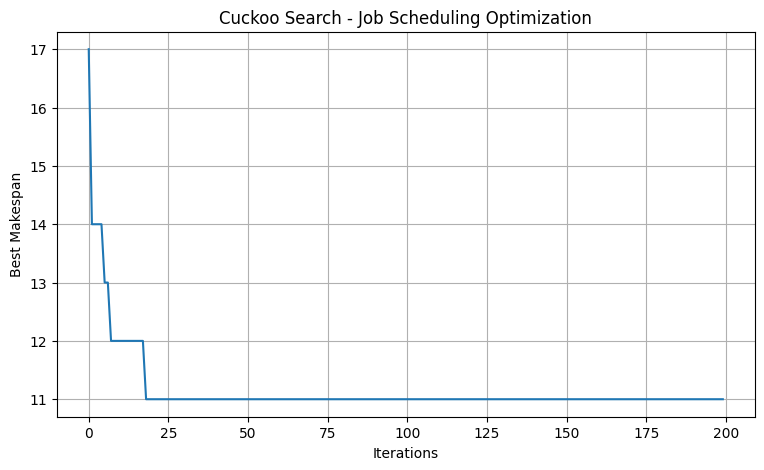

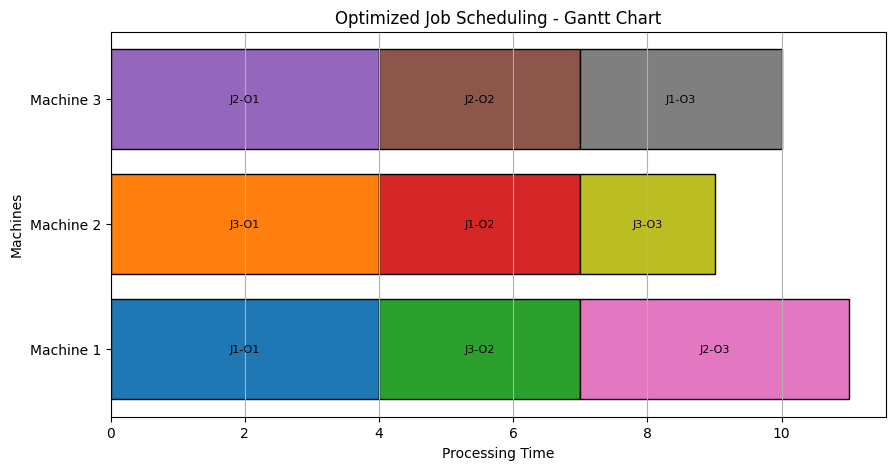

In [ ]:

import numpy as np
import random
import math
import matplotlib.pyplot as plt

# ==========================================
# 1. JOB SHOP PROBLEM DEFINITION
# ==========================================

# Each operation has:
# predecessors: operations that must finish first
# machines: eligible machines and their processing times

operations = {
    "J1-O1": {"pred": [], "machines": {0: 4, 1: 5}},
    "J1-O2": {"pred": [], "machines": {1: 3, 2: 4}},
    "J1-O3": {"pred": ["J1-O1", "J1-O2"],
              "machines": {0: 5, 2: 3}},

    "J2-O1": {"pred": [], "machines": {0: 3, 2: 4}},
    "J2-O2": {"pred": ["J2-O1"],
              "machines": {1: 5, 2: 3}},
    "J2-O3": {"pred": ["J2-O2"],
              "machines": {0: 4, 1: 3}},

    "J3-O1": {"pred": [], "machines": {1: 4, 2: 3}},
    "J3-O2": {"pred": ["J3-O1"],
              "machines": {0: 3, 1: 5}},
    "J3-O3": {"pred": ["J3-O1"],
              "machines": {1: 2, 2: 4}}
}

op_names = list(operations.keys())
N = len(op_names)
machine_count = 3

# ==========================================
# 2. CUCKOO SEARCH PARAMETERS
# ==========================================

n_nests = 25
pa = 0.25
iterations = 200

random.seed(42)
np.random.seed(42)

# ==========================================
# 3. INITIALIZE A NEST
# ==========================================

def create_nest():

    # Random operation sequence
    sequence = random.sample(op_names, N)

    # Random eligible machine for each operation
    assignment = {}

    for op in op_names:
        eligible = list(operations[op]["machines"].keys())
        assignment[op] = random.choice(eligible)

    return {
        "sequence": sequence,
        "assignment": assignment
    }


# ==========================================
# 4. SCHEDULE DECODER AND FITNESS
# ==========================================

def evaluate(nest):

    sequence = nest["sequence"]
    assignment = nest["assignment"]

    completed = {}
    machine_available = [0] * machine_count
    schedule = {}

    # Build a valid topological operation order
    remaining = sequence.copy()
    valid_order = []

    while remaining:

        ready = [
            op for op in remaining
            if all(p in completed for p in operations[op]["pred"])
        ]

        if not ready:
            raise ValueError("Invalid precedence graph")

        # Choose the highest-priority ready operation
        op = ready[0]

        remaining.remove(op)
        valid_order.append(op)
        completed[op] = True

    # Reset completion information
    completed = {}

    # Schedule each operation
    for op in valid_order:

        machine = assignment[op]

        duration = operations[op]["machines"][machine]

        # Earliest start from predecessor completion
        predecessor_finish = max(
            [completed[p] for p in operations[op]["pred"]],
            default=0
        )

        start = max(
            predecessor_finish,
            machine_available[machine]
        )

        finish = start + duration

        schedule[op] = {
            "machine": machine,
            "start": start,
            "finish": finish,
            "duration": duration
        }

        completed[op] = finish
        machine_available[machine] = finish

    makespan = max(completed.values())

    return makespan, schedule


# ==========================================
# 5. LEVY FLIGHT
# ==========================================

def levy_flight():

    beta = 1.5

    sigma = (
        math.gamma(1 + beta) *
        math.sin(math.pi * beta / 2) /
        (
            math.gamma((1 + beta) / 2) *
            beta *
            2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / (abs(v) ** (1 / beta))


# ==========================================
# 6. GENERATE NEW SOLUTION
# ==========================================

def generate_new_solution(nest):

    new_nest = {
        "sequence": nest["sequence"].copy(),
        "assignment": nest["assignment"].copy()
    }

    # Levy flight determines mutation intensity
    step = abs(levy_flight())

    changes = min(
        N,
        max(1, int(step * 2) + 1)
    )

    # Change operation sequence using swaps
    for _ in range(changes):

        i, j = random.sample(range(N), 2)

        new_nest["sequence"][i], \
        new_nest["sequence"][j] = \
        new_nest["sequence"][j], \
        new_nest["sequence"][i]

    # Change machine assignments
    for _ in range(changes):

        op = random.choice(op_names)

        eligible = list(operations[op]["machines"].keys())

        new_nest["assignment"][op] = random.choice(eligible)

    return new_nest


# ==========================================
# 7. INITIALIZE POPULATION
# ==========================================

nests = [create_nest() for _ in range(n_nests)]

fitness = [
    evaluate(nest)[0] for nest in nests
]

best_index = np.argmin(fitness)

best_nest = {
    "sequence": nests[best_index]["sequence"].copy(),
    "assignment": nests[best_index]["assignment"].copy()
}

best_fitness = fitness[best_index]

history = []


# ==========================================
# 8. MAIN CUCKOO SEARCH LOOP
# ==========================================

for t in range(iterations):

    # Generate new solutions
    for i in range(n_nests):

        new_nest = generate_new_solution(nests[i])

        new_fitness, _ = evaluate(new_nest)

        # Randomly select a nest
        j = random.randrange(n_nests)

        if new_fitness < fitness[j]:

            nests[j] = new_nest
            fitness[j] = new_fitness

    # Sort nests by fitness
    sorted_indices = np.argsort(fitness)

    # Abandon the worst nests
    abandon_count = int(pa * n_nests)

    for idx in sorted_indices[-abandon_count:]:

        nests[idx] = create_nest()
        fitness[idx] = evaluate(nests[idx])[0]

    # Update best solution
    current_index = np.argmin(fitness)

    if fitness[current_index] < best_fitness:

        best_fitness = fitness[current_index]

        best_nest = {
            "sequence": nests[current_index]["sequence"].copy(),
            "assignment": nests[current_index]["assignment"].copy()
        }

    history.append(best_fitness)

# ==========================================
# 9. DISPLAY OPTIMIZED RESULT
# ==========================================

best_makespan, best_schedule = evaluate(best_nest)

print("\n========== OPTIMIZED JOB SCHEDULE ==========")

for op, details in best_schedule.items():

    print(
        op,
        "| Machine:", details["machine"] + 1,
        "| Start:", details["start"],
        "| Finish:", details["finish"],
        "| Duration:", details["duration"]
    )

print("\nBest Operation Sequence:")
print(best_nest["sequence"])

print("\nBest Machine Assignment:")
for op, machine in best_nest["assignment"].items():
    print(op, "-> Machine", machine + 1)

print("\nMinimum Makespan:", best_makespan)

# ==========================================
# 10. CONVERGENCE GRAPH
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(history)

plt.xlabel("Iterations")
plt.ylabel("Best Makespan")
plt.title("Cuckoo Search - Job Scheduling Optimization")

plt.grid()
plt.show()


# ==========================================
# 11. GANTT CHART
# ==========================================

plt.figure(figsize=(10, 5))

for op, details in best_schedule.items():

    machine = details["machine"]
    start = details["start"]
    duration = details["duration"]

    plt.barh(
        machine,
        duration,
        left=start,
        edgecolor="black"
    )

    plt.text(
        start + duration / 2,
        machine,
        op,
        ha="center",
        va="center",
        fontsize=8
    )

plt.yticks(
    range(machine_count),
    [f"Machine {i+1}" for i in range(machine_count)]
)

plt.xlabel("Processing Time")
plt.ylabel("Machines")
plt.title("Optimized Job Scheduling - Gantt Chart")
plt.grid(axis="x")

plt.show()
